In [2]:
!pip install numpy
!pip install pymc
!pip install arviz
!pip install scipy

Output()

posterior exact: Gamma(alpha=182, beta=10.1)
media posteriorului: 18.01980198019802
modul posteriorului: 17.92079207920792
hdi 94% exact: [15.52872639 20.54857462]


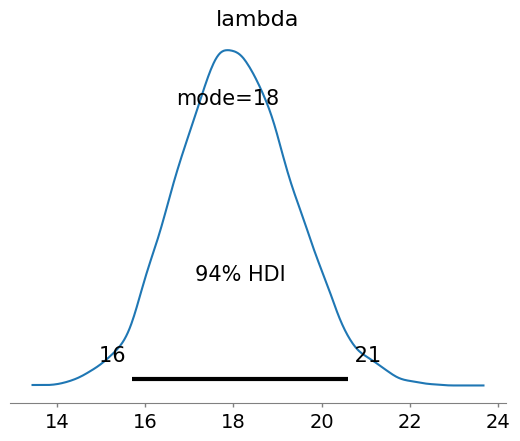

hdi 94% (pymc): <xarray.Dataset> Size: 64B
Dimensions:  (hdi: 2)
Coordinates:
  * hdi      (hdi) <U6 48B 'lower' 'higher'
Data variables:
    lambda   (hdi) float64 16B 15.7 20.6
Attributes:
    created_at:                 2026-11-19T20:33:05.874788+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.28.5
    sampling_time:              9.207950592041016
    tuning_steps:               1000


In [3]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats

# date observate: 180 de apeluri in 10 ore
total_calls = 180
hours = 10

# ---------------- alegerea distributiei a priori ----------------

# alegem o gamma(alpha, beta) pentru lambda, pentru ca e conjugata distributiei poisson
# media priorului e alpha/beta, iar dispersia e alpha/beta^2
# alegem parametri care dau un prior larg (slab informativ): media 20, dispersie mare
# astfel datele domina rezultatul, iar priorul nu "trage" estimarea intr-o parte
alpha_prior = 2
beta_prior = 0.1   # media = 2 / 0.1 = 20, deviatia standard = sqrt(2) / 0.1 ~ 14


# ---------------- model in pymc ----------------

with pm.Model() as model:
    # prior pentru rata medie de apeluri pe ora
    # atentie: in pymc, Gamma(alpha, beta) foloseste beta ca rata, ca in enunt
    lam = pm.Gamma("lambda", alpha=alpha_prior, beta=beta_prior)

    # verosimilitatea: apelurile pe 10 ore sunt poisson cu media lambda * 10
    # (suma de variabile poisson independente e tot poisson, cu parametrul adunat)
    calls = pm.Poisson("calls", mu=lam * hours, observed=total_calls)

    # esantionam din distributia a posteriori
    idata = pm.sample(4000, tune=1000, chains=4, random_seed=42)


# ---------------- distributia a posteriori exacta ----------------

# datorita conjugarii, posteriorul se poate scrie direct, fara esantionare:
# gamma(alpha + suma apelurilor, beta + numarul de ore)
alpha_post = alpha_prior + total_calls
beta_post = beta_prior + hours
print(f"posterior exact: Gamma(alpha={alpha_post}, beta={beta_post})")
print("media posteriorului:", alpha_post / beta_post)
# modul unei gamma e (alpha - 1) / beta, daca alpha > 1
print("modul posteriorului:", (alpha_post - 1) / beta_post)

# interval hdi 94% din posteriorul exact (esantionam mult din el)
exact = stats.gamma(a=alpha_post, scale=1 / beta_post)
exact_samples = exact.rvs(200000, random_state=42)
print("hdi 94% exact:", az.hdi(exact_samples, hdi_prob=0.94))


# ---------------- hdi si mod cu arviz ----------------

# plot_posterior afiseaza distributia, intervalul hdi de 94% si valoarea cea mai probabila
az.plot_posterior(idata, var_names=["lambda"], hdi_prob=0.94, point_estimate="mode")
plt.savefig("posterior_lambda.png")
plt.show()

# acelasi hdi, dar ca numere, calculat din esantioanele pymc
print("hdi 94% (pymc):", az.hdi(idata, var_names=["lambda"], hdi_prob=0.94))